In [2]:
#Sentiment Analysis — IMDb Movie Reviews 
#Naive Bayes, Logistic Regression, and SVM 
# ---------- Step 1: Import libraries ----------
import re
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [3]:
# ---------- Step 2: Load the dataset ----------
data = pd.read_csv(r"C:\Users\katta\OneDrive\Documents\IMDB Dataset.csv\IMDB Dataset.csv")      # columns: review, sentiment
print("Total reviews:", len(data))
print(data["sentiment"].value_counts())     # check positive/negative count
# ---------- Step 3: Text preprocessing ----------
def clean_text(text):
    text = text.lower()                      # lowercase
    text = re.sub(r"<.*?>", " ", text)       # remove HTML tags like <br />
    text = re.sub(r"[^a-z\s]", "", text)     # keep only letters and spaces
    return text
data["clean_review"] = data["review"].apply(clean_text)
# convert labels to numbers: positive = 1, negative = 0
data["label"] = data["sentiment"].map({"positive": 1, "negative": 0})
print(data.head())

Total reviews: 50000
sentiment
positive    25000
negative    25000
Name: count, dtype: int64
                                              review sentiment  \
0  One of the other reviewers has mentioned that ...  positive   
1  A wonderful little production. <br /><br />The...  positive   
2  I thought this was a wonderful way to spend ti...  positive   
3  Basically there's a family where a little boy ...  negative   
4  Petter Mattei's "Love in the Time of Money" is...  positive   

                                        clean_review  label  
0  one of the other reviewers has mentioned that ...      1  
1  a wonderful little production   the filming te...      1  
2  i thought this was a wonderful way to spend ti...      1  
3  basically theres a family where a little boy j...      0  
4  petter matteis love in the time of money is a ...      1  


In [4]:
# ---------- Step 4: Split into training and testing ----------
X_train, X_test, y_train, y_test = train_test_split(
    data["clean_review"], data["label"],
    test_size=0.2, random_state=42, stratify=data["label"]
)

In [5]:

# ---------- Step 5: TF-IDF (text to numbers) ----------
tfidf = TfidfVectorizer(stop_words="english", max_features=5000)
X_train_tfidf = tfidf.fit_transform(X_train)   # learn words + convert
X_test_tfidf = tfidf.transform(X_test)         # only convert



In [6]:
# ---------- Step 6: Train the three models ----------
models = {
    "Naive Bayes": MultinomialNB(),
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "SVM": LinearSVC(),
}

for name, model in models.items():
    model.fit(X_train_tfidf, y_train)                  # training
    predictions = model.predict(X_test_tfidf)          # testing
    accuracy = accuracy_score(y_test, predictions)
    print(f"{name} Accuracy: {accuracy:.4f}")



Naive Bayes Accuracy: 0.8528
Logistic Regression Accuracy: 0.8888
SVM Accuracy: 0.8807


In [7]:
# ---------- Step 7: Detailed report for the best model ----------
best_model = models["Logistic Regression"]
best_pred = best_model.predict(X_test_tfidf)

print("\nClassification Report:")
print(classification_report(y_test, best_pred, target_names=["Negative", "Positive"]))

print("Confusion Matrix:")
print(confusion_matrix(y_test, best_pred))




Classification Report:
              precision    recall  f1-score   support

    Negative       0.90      0.88      0.89      5000
    Positive       0.88      0.90      0.89      5000

    accuracy                           0.89     10000
   macro avg       0.89      0.89      0.89     10000
weighted avg       0.89      0.89      0.89     10000

Confusion Matrix:
[[4404  596]
 [ 516 4484]]


In [8]:
# ---------- Step 8: Predict your own review ----------
def predict_sentiment(review):
    review = clean_text(review)
    numbers = tfidf.transform([review])
    result = best_model.predict(numbers)[0]
    confidence = best_model.predict_proba(numbers)[0].max()
    label = "Positive" if result == 1 else "Negative"
    return f"{label} ({confidence:.0%} sure)"
print("\n", predict_sentiment("This movie was amazing, I loved every minute!"))
print(" ", predict_sentiment("Worst film ever, a complete waste of time."))

# Type your own review
user_review = input("\nEnter a movie review: ")
print("Result:", predict_sentiment(user_review))


 Positive (99% sure)
  Negative (100% sure)



Enter a movie review:  movie is bad


Result: Negative (100% sure)


C:\Users\katta\AppData\Local\Temp\ipykernel_17768\1788121490.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x="sentiment", data=data, palette=["tomato", "seagreen"])


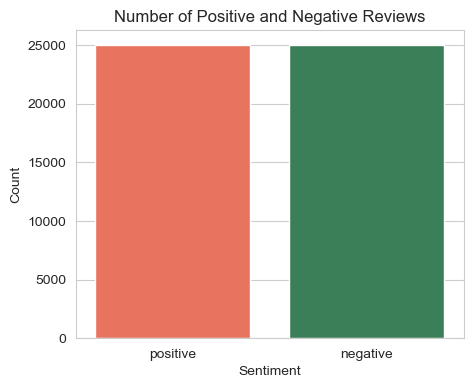

In [20]:
# ---------- Step 9: Visualizations ----------
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_curve, auc

sns.set_style("whitegrid")
# ===== Graph 1: Positive vs Negative reviews in the dataset =====
plt.figure(figsize=(5, 4))
sns.countplot(x="sentiment", data=data, palette=["tomato", "seagreen"])
plt.title("Number of Positive and Negative Reviews")
plt.xlabel("Sentiment")
plt.ylabel("Count")
plt.show()

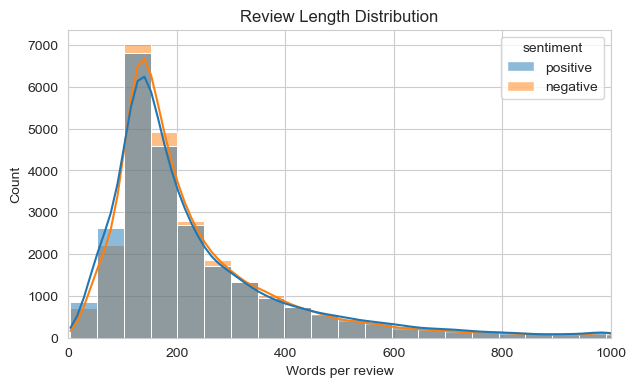

In [12]:
# ===== Graph 2: Review length (number of words) =====
data["word_count"] = data["review"].str.split().str.len()

plt.figure(figsize=(7, 4))
sns.histplot(data=data, x="word_count", hue="sentiment", bins=50, kde=True)
plt.xlim(0, 1000)
plt.title("Review Length Distribution")
plt.xlabel("Words per review")
plt.show()

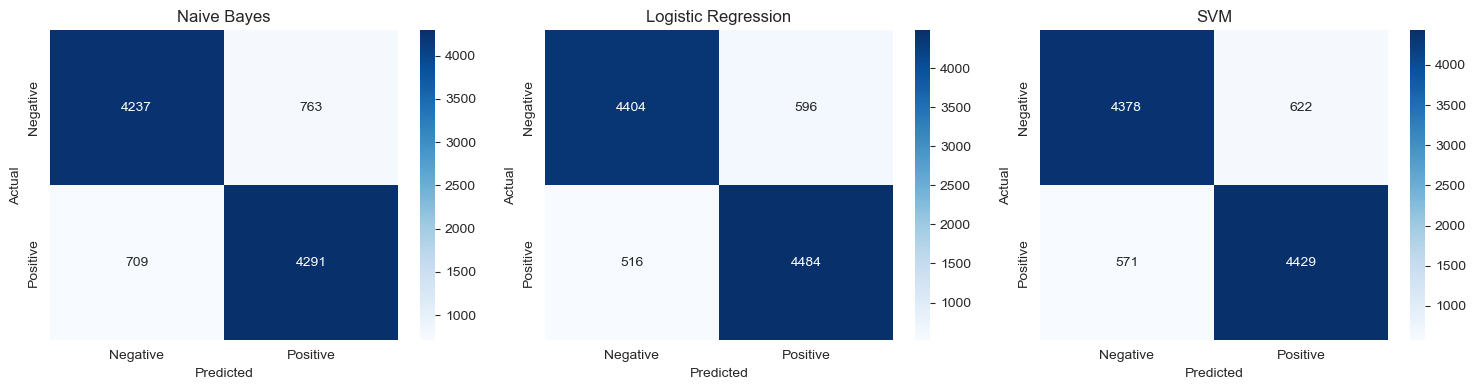

In [13]:
# ===== Graph 3: Confusion matrix of all three models =====
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (name, model) in zip(axes, models.items()):
    pred = model.predict(X_test_tfidf)
    cm = confusion_matrix(y_test, pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax,
                xticklabels=["Negative", "Positive"],
                yticklabels=["Negative", "Positive"])
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()

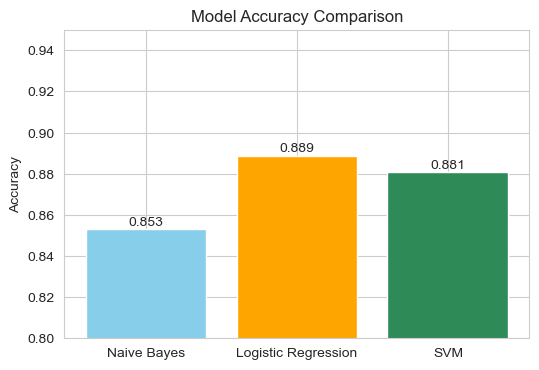

In [14]:
# ===== Graph 4: Accuracy comparison of the models =====
names, scores = [], []
for name, model in models.items():
    names.append(name)
    scores.append(accuracy_score(y_test, model.predict(X_test_tfidf)))

plt.figure(figsize=(6, 4))
bars = plt.bar(names, scores, color=["skyblue", "orange", "seagreen"])
plt.ylim(0.80, 0.95)
plt.title("Model Accuracy Comparison")
plt.ylabel("Accuracy")
for bar, score in zip(bars, scores):
    plt.text(bar.get_x() + bar.get_width() / 2, score + 0.002,
             f"{score:.3f}", ha="center")
plt.show()


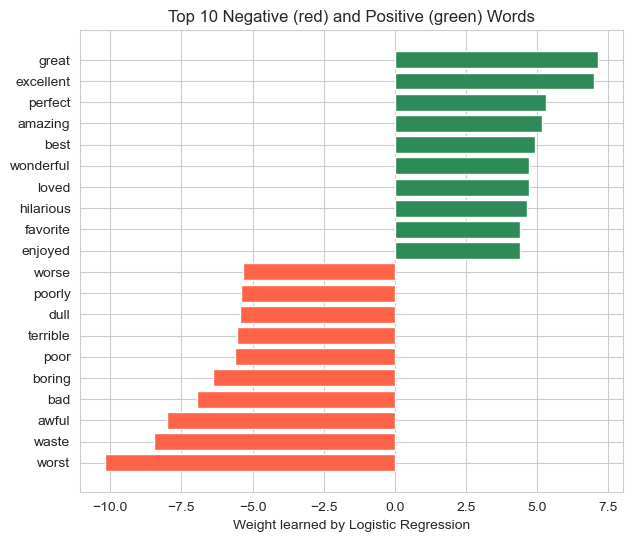

In [15]:

# ===== Graph 5: Top words that decide the sentiment =====
words = np.array(tfidf.get_feature_names_out())
weights = best_model.coef_[0]
order = weights.argsort()

top_words = np.concatenate([words[order[:10]], words[order[-10:]]])
top_weights = np.concatenate([weights[order[:10]], weights[order[-10:]]])
colors = ["tomato"] * 10 + ["seagreen"] * 10

plt.figure(figsize=(7, 6))
plt.barh(top_words, top_weights, color=colors)
plt.title("Top 10 Negative (red) and Positive (green) Words")
plt.xlabel("Weight learned by Logistic Regression")
plt.show()

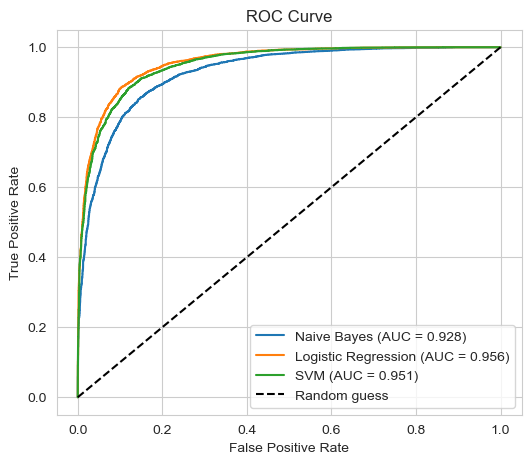

In [16]:
# ===== Graph 6: ROC curve =====
plt.figure(figsize=(6, 5))
for name, model in models.items():
    if hasattr(model, "predict_proba"):
        scores_roc = model.predict_proba(X_test_tfidf)[:, 1]
    else:
        scores_roc = model.decision_function(X_test_tfidf)   # for SVM
    fpr, tpr, _ = roc_curve(y_test, scores_roc)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc(fpr, tpr):.3f})")

plt.plot([0, 1], [0, 1], "k--", label="Random guess")
plt.title("ROC Curve")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.show()